# 🔑 Solutions · Lesson 01: Time-Series Fundamentals

> Try every problem yourself first! Peek at hints before peeking here. Run the setup cell, then read each solution **and its explanation**: there is often more than one valid way.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

In [2]:
from statsmodels.tsa.stattools import adfuller, kpss
maize = load_weekly("maize")

def adf_report(x, name="series"):
    x = pd.Series(x).dropna()
    stat, p, *_ = adfuller(x, autolag="AIC")
    print(f"ADF  | {name:<28} | stat={stat:7.2f}  p={p:.4f} | {'stationary' if p < 0.05 else 'NON-stationary'}")

def kpss_report(x, name="series"):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(x, regression="c", nlags="auto")
    print(f"KPSS | {name:<28} | stat={stat:7.2f}  p={p:.4f} | {'stationary' if p > 0.05 else 'NON-stationary'}")

### ✅ Solution 1.1 · Which crop is most seasonal?

**Problem recap:** For each of the four commodities, decompose the **log price** with `STL(period=52, robust=True)` and compute the
  **seasonal strength** `max(0, 1 - Var(residual) / Var(seasonal + residual))` (the formula from the worked example).
  Print the four strengths from strongest to weakest.

In [3]:
from statsmodels.tsa.seasonal import STL
strength = {}
for name in ['maize', 'tomato', 'onion', 'rice']:
    s = load_weekly(name)['price']
    res = STL(np.log(s), period=52, robust=True).fit()
    strength[name] = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
pd.Series(strength).sort_values(ascending=False).round(3)

onion     0.869
tomato    0.765
maize     0.757
rice      0.533
dtype: float64

**Why this works:** Seasonal strength near 1 means the seasonal wave dominates what is left after removing the trend; near 0 means seasonality is negligible. We use the *log* price so the seasonal swing is measured as a percentage, which is comparable across crops of different price levels.

### ✅ Solution 1.2 · Is tomato stationary?

**Problem recap:** Use the helpers `adf_report` and `kpss_report` (defined in the worked example) to test the **tomato price level** and the **weekly log change** of tomato prices.
  Does tomato need differencing? Then compute the lag-1 autocorrelation of the differenced series and explain (in a comment) why differencing might be a *mistake* here.

In [4]:
from statsmodels.tsa.stattools import acf
tomato = load_weekly('tomato')['price']
d = np.log(tomato).diff().dropna()
adf_report(tomato, 'tomato price level'); kpss_report(tomato, 'tomato price level')
adf_report(d, 'tomato weekly log change'); kpss_report(d, 'tomato weekly log change')
print('lag-1 autocorrelation of the differenced series:', round(acf(d, nlags=1)[1], 3))

ADF  | tomato price level           | stat=  -3.58  p=0.0061 | stationary
KPSS | tomato price level           | stat=   0.28  p=0.1000 | stationary
ADF  | tomato weekly log change     | stat= -11.21  p=0.0000 | stationary
KPSS | tomato weekly log change     | stat=   0.01  p=0.1000 | stationary
lag-1 autocorrelation of the differenced series: -0.161


**Why this works:** Both tests agree that tomato prices are **already stationary in levels** (ADF rejects the unit root, KPSS does not reject stationarity). Tomato prices swing around a fairly stable level instead of drifting away. Differencing would still pass the tests, but it is *over-differencing*: the differenced series has a clearly negative lag-1 autocorrelation (≈ −0.16), an artefact we created. Contrast with maize, where the level fails both tests. Moral: **test each series separately: do not copy the differencing order from one commodity to another.** Always read ADF and KPSS *together*: ADF wants a small p-value, KPSS a large one.

### ✅ Solution 1.3 · Autocorrelation by hand

**Problem recap:** Without using `acf()`, compute the **lag-1, lag-4 and lag-52 autocorrelation** of the **weekly log change** of maize prices
  using `np.corrcoef`. Then confirm with `statsmodels.tsa.stattools.acf`. Store the lag-1 value in `lag1`.

In [5]:
from statsmodels.tsa.stattools import acf
x = np.log(maize['price']).diff().dropna().values
manual = {k: np.corrcoef(x[k:], x[:-k])[0, 1] for k in (1, 4, 52)}
auto = acf(x, nlags=52)
for k in (1, 4, 52):
    print(f'lag {k:>2}: manual={manual[k]: .3f}   statsmodels={auto[k]: .3f}')
lag1 = manual[1]

lag  1: manual= 0.024   statsmodels= 0.024
lag  4: manual= 0.128   statsmodels= 0.127
lag 52: manual= 0.185   statsmodels= 0.174


**Why this works:** An autocorrelation is just a correlation between a series and a lagged copy of itself. For maize the lag-1 autocorrelation of weekly changes is close to zero (week-to-week moves are nearly unpredictable), but lag 4 is clearly positive (slow-moving supply shocks such as rain and fuel unfold over weeks) and lag 52 is positive too: the *seasonal pattern repeats every year*, so this week's change resembles the change 52 weeks ago. This is why seasonal terms matter later in SARIMA.

### ✅ Solution 1.4 · Mystery process

**Problem recap:** The function below produces a mystery series. **Without looking at the code inside**, use ACF and PACF plots to decide whether it is
  AR(1), AR(2), MA(1) or white noise, and estimate its main coefficient.

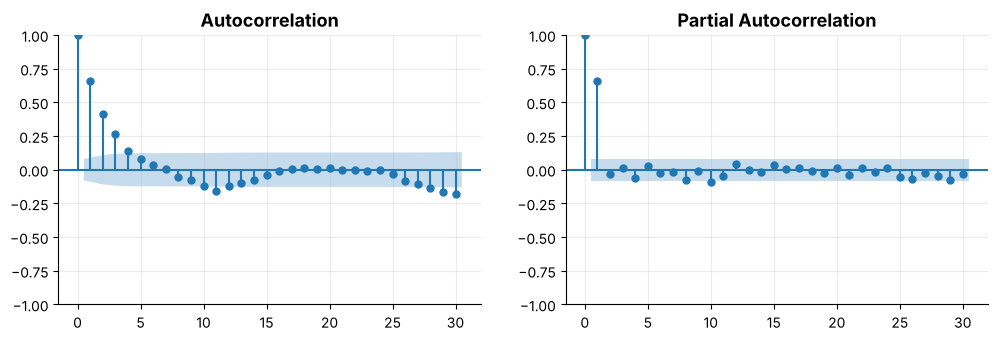

PACF lag1 ≈ 0.655  (true φ = 0.7)


In [6]:
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
def mystery(n=600, seed=11):
    rng = np.random.default_rng(seed)
    return pd.Series(ArmaProcess(ar=[1, -0.7, 0.0], ma=[1]).generate_sample(n, distrvs=lambda size: rng.standard_normal(size)))
m = mystery()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(m, lags=30, ax=ax[0]); plot_pacf(m, lags=30, ax=ax[1], method='ywm'); plt.show()
from statsmodels.tsa.stattools import pacf
print('PACF lag1 ≈', round(pacf(m, nlags=3, method='ywm')[1], 3), ' (true φ = 0.7)')

**Why this works:** The ACF decays geometrically (0.7, 0.49, 0.34, …) while the PACF has a single big spike at lag 1 and then falls inside the blue band. That is the fingerprint of **AR(1)**: lag 1 explains everything lag 2, 3, … would add.

### ✅ Solution 1.5 · Find the solar cycle

**Problem recap:** `load_sunspots()` below returns the annual sunspot counts from 1700 onwards. Astronomers say there is a ~11-year solar cycle.
  Use autocorrelation (**not** a plot you eyeball) to estimate the cycle length in years (you should land around 10–11). Is this *seasonality* or *cyclicality*? Why?

Estimated cycle length: 10 years (ACF at 10 and 11 years are nearly equal; the textbook value is ~11)


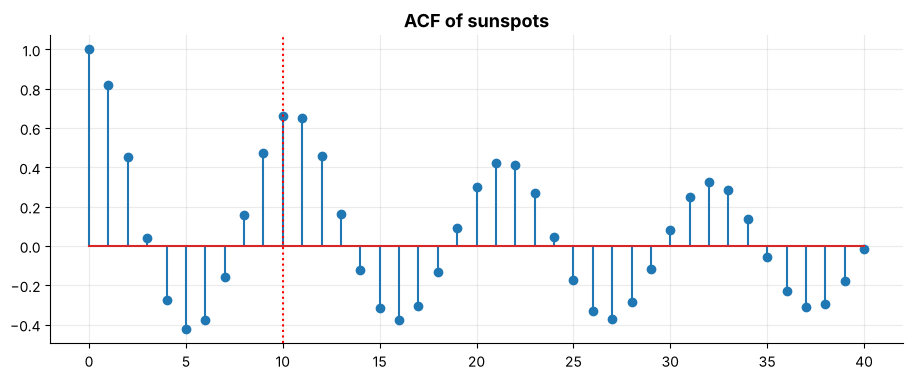

In [7]:
from statsmodels.tsa.stattools import acf
def load_sunspots():
    return pd.read_csv(DATA / 'sunspots_annual.csv').set_index('year')['sunspots']
s = load_sunspots()
a = acf(s, nlags=40)
peak = int(np.argmax(a[5:21]) + 5)
print('Estimated cycle length:', peak, 'years (ACF at 10 and 11 years are nearly equal; the textbook value is ~11)')
plt.stem(a); plt.axvline(peak, color='red', ls=':'); plt.title('ACF of sunspots'); plt.show()

**Why this works:** The ACF of a cyclical series oscillates: it is high when the lag matches the cycle length and negative at half the cycle. Because individual solar cycles last between ~9 and ~14 years, the cycle is *cyclical* (irregular period), not seasonal (fixed period). In agriculture, multi-year price cycles ('cobweb' cycles when high prices make everyone plant more, which then crashes prices) are cyclical too.